In [1]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [2]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

mariaspasyuk_simpsons_path = kagglehub.dataset_download('mariaspasyuk/simpsons')
#KGAT_e8056575ce79f125b4cf864bad157aad

print('Data source import complete.')


100%|██████████| 486M/486M [00:13<00:00, 38.0MB/s]

Extracting files...


Data source import complete.


Импортируем необходимые библиотеки.

In [3]:
import os
import torch
import glob
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch.nn as nn
from transformers import AutoImageProcessor, AutoModelForImageClassification, TrainingArguments, Trainer
from datasets import Dataset as HFDataset
import numpy as np
from sklearn.metrics import accuracy_score, classification_report
from collections import defaultdict
import wandb
import random
from tqdm import tqdm, tqdm_notebook
from torch.utils.data import Subset
import warnings
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd

np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{device=}")

device=device(type='cuda')


**1.1 Transfer learning**

1.1.1 Выберите одну из трансформерных классификационных моделей, доступных на HF. Обоснуйте свой выбор модели. Возможные критерии для выбора - релевантность обучающих данных, точность классификации, размер модели, требуемые ресурсы для обучения.

Возьмем модель microsoft/beit-base-patch16-224, так как:
- она обучена на ImageNet-21k (14 million images, 21,841 classes)
- выполнен fine-tuning на ImageNet 2012 (1 million images, 1,000 classes)
То есть модель обучена на огромном количестве изображений различных классов.
- модель относительно небольшая (87M params), значит будет обучаться довольно быстро и хватит ресурсов gpu.
- Совместима с Hugging Face Transformers (AutoModelForImageClassification)

In [4]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
model_name = "microsoft/beit-base-patch16-224"
processor = AutoImageProcessor.from_pretrained(model_name)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/276 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


1.1.2 Для выбранной модели выполните хотя бы один вариант transfer learning для решения поставленной задачи. Используя инструменты HF и библиотеки transformers напишите код для подгрузки и обработки данных, обучения и инференса модели, логирования результатов. Оцените полученное качество классификации, сравните с результатами, полученными в HW2.


Напишем классы SimpsonsTrainDataset и SimpsonsTestDataset для создания датасетов подходящего формата. Так как в структура train_dataset и test_dataset различается, придется написать 2 разных класса.

In [5]:
class SimpsonsTrainDataset(Dataset):
    def __init__(self, data_dir, processor, split="train"):
        self.data_dir = data_dir
        self.processor = processor
        self.split = split

        self.samples = []
        self.class_to_idx = {}
        self.idx_to_class = {}

        classes = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(classes)}
        self.idx_to_class = {idx: cls_name for cls_name, idx in self.class_to_idx.items()}

        for class_name in classes:
            class_dir = os.path.join(data_dir, class_name)
            for img_name in os.listdir(class_dir):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.samples.append((os.path.join(class_dir, img_name), self.class_to_idx[class_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        inputs = self.processor(image, return_tensors="pt")

        return {'pixel_values': inputs['pixel_values'].squeeze(), 'labels': torch.tensor(label, dtype=torch.long)}

In [6]:
class SimpsonsTestDataset(Dataset):
    def __init__(self, test_dir, processor, class_to_idx):
        self.test_dir = test_dir
        self.processor = processor
        self.class_to_idx = class_to_idx

        self.samples = []
        test_images = glob.glob(os.path.join(test_dir, "*.jpg")) + \
                     glob.glob(os.path.join(test_dir, "*.png")) + \
                     glob.glob(os.path.join(test_dir, "*.jpeg"))

        for img_path in test_images:
            filename = os.path.basename(img_path)
            class_name = '_'.join(filename.split('_')[:-1])
            #print(class_name)

            if class_name in self.class_to_idx:
                label = self.class_to_idx[class_name]
                self.samples.append((img_path, label, filename))
            else:
                print(f"Unknown class {class_name} in file {filename}")
                continue

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label, filename = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        inputs = self.processor(image, return_tensors="pt")

        return {
            'pixel_values': inputs['pixel_values'].squeeze(), 'labels': torch.tensor(label, dtype=torch.long), 'filename': filename}


In [7]:
num_classes = 20
batch_size = 64
img_size = 224

processor.size = img_size

train_dataset = SimpsonsTrainDataset("/root/.cache/kagglehub/datasets/mariaspasyuk/simpsons/versions/1/train_dataset", processor)
test_dataset = SimpsonsTestDataset("/root/.cache/kagglehub/datasets/mariaspasyuk/simpsons/versions/1/test_dataset", processor, train_dataset.class_to_idx)

print(f"Train samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Classes: {train_dataset.idx_to_class}")

Train samples: 19548
Test samples: 990
Classes: {0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson', 3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel', 7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lenny_leonard', 11: 'lisa_simpson', 12: 'marge_simpson', 13: 'mayor_quimby', 14: 'milhouse_van_houten', 15: 'moe_szyslak', 16: 'ned_flanders', 17: 'nelson_muntz', 18: 'principal_skinner', 19: 'sideshow_bob'}


из HW2: Датасет сильно несбалансирован по классам. Например, класс mayor_quimby составляет примерно 0.1 от класса homer_simpson, что при обучении модели будет играть роль. Поэтому из всего тренировочного датасета возьмем только по 200-600 изображений каждого класса, чтобы распределение было чуть равномернее, дабы не создавать ситуации, когда модель хорошо определяет только самые объемные по количеству картинок классы исходного датасета.

В HW2 был проанализирован датасет и было сказано, что он сильно несбалансированный по классам. Применим тот же метод отбора картинок каждого класса, что и тогда. Будем брать все изображения класса, если их меньше 600, будем брать рандомное количество от 500 до 600 изображений в противном случае. Так наши данные будут более сбалансированные.

In [8]:
class_indices = defaultdict(list)

for idx in range(len(train_dataset)):
    sample = train_dataset[idx]
    target = sample['labels'].item()
    class_indices[target].append(idx)

selected_indices = []

for cls, indices in class_indices.items():
    count = len(indices)
    class_name = train_dataset.idx_to_class[cls]

    if count < 600:
        selected_indices.extend(indices)
    else:
        sample_size = random.randint(500, 600)
        sampled = random.sample(indices, sample_size)
        selected_indices.extend(sampled)
random.shuffle(selected_indices)

balanced_train = Subset(train_dataset, selected_indices)
print(f"Final size of train dataset is: {len(balanced_train)}")

Final size of train dataset is: 10055


**1.2 Zero-shot classification**

1.2.1 Примените три модели (OpenaAI-CLIP, SigLIP2, MetaCLIP2) к валидационным данным в режиме zero-shot классификации. Оцените полученное качество классификации и сравните модели между собой, дайте содержательный комментарий. Также сравните модели с моделью из предыдущего пункта и из HW2.


**OpenaAI-CLIP**

In [ ]:
from transformers import CLIPProcessor, CLIPModel

model_openai = CLIPModel.from_pretrained("openai/clip-vit-large-patch14").to(device)
processor_openai = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [ ]:
print(model_openai)

CLIPModel(
  (text_model): CLIPTextTransformer(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 768)
      (position_embedding): Embedding(77, 768)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-05,

In [ ]:
candidate_labels = list(train_dataset.idx_to_class.values())

In [ ]:
candidate_labels

['abraham_grampa_simpson',
 'apu_nahasapeemapetilon',
 'bart_simpson',
 'charles_montgomery_burns',
 'chief_wiggum',
 'comic_book_guy',
 'edna_krabappel',
 'homer_simpson',
 'kent_brockman',
 'krusty_the_clown',
 'lenny_leonard',
 'lisa_simpson',
 'marge_simpson',
 'mayor_quimby',
 'milhouse_van_houten',
 'moe_szyslak',
 'ned_flanders',
 'nelson_muntz',
 'principal_skinner',
 'sideshow_bob']

In [ ]:
candidate_labels = [label.replace('_', ' ') for label in candidate_labels]

In [ ]:
def evaluate_zero_shot(model, processor, test_dataset, candidate_labels, class_mapping=None):
    model.to(device)
    model.eval()

    test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    all_probabilities = []
    all_predictions = []
    all_true = []
    all_confidences = []
    candidate_labels_prompt = ['a photo of ' + label + ' from simpsons' for label in candidate_labels ]

    with torch.no_grad():
        for data in test_dataloader:
            pixel_values = data['pixel_values'].to(device)
            true_labels = data['labels'].cpu().numpy()

            text_inputs = processor(text=candidate_labels_prompt, return_tensors="pt", padding=True).to(device)

            batch_predictions = []
            batch_probabilities = []

            for i in range(pixel_values.shape[0]):
                single_image = pixel_values[i].unsqueeze(0)
                try:
                    outputs = model(input_ids=text_inputs['input_ids'],attention_mask=text_inputs['attention_mask'], pixel_values=single_image)
                except:
                    outputs = model(**text_inputs, pixel_values=single_image)

                logits_per_image = outputs.logits_per_image
                probs = logits_per_image.softmax(dim=1)
                predicted_class_idx = torch.argmax(probs, dim=1).item()

                batch_predictions.append(predicted_class_idx)
                batch_probabilities.append(probs.cpu().numpy())

            all_true.extend(true_labels)
            all_predictions.extend(batch_predictions)
            all_probabilities.extend(batch_probabilities)

    text_predictions = [candidate_labels[pred] for pred in all_predictions]
    text_true = [candidate_labels[true] for true in all_true]

    correct_predictions = [true == pred for true, pred in zip(text_true, text_predictions)]
    accuracy = np.mean(correct_predictions)

    print(f"Zero-shot accuracy on test samples: {accuracy:.4f}")

    print(f"Classification Report:")
    report = classification_report(text_true, text_predictions, zero_division=0, digits=4)
    print(report)

    unique_preds, pred_counts = np.unique(text_predictions, return_counts=True)
    unique_true, true_counts = np.unique(text_true, return_counts=True)

    print(f"Prediction Distribution:")
    for label in candidate_labels:
        pred_count = pred_counts[unique_preds == label][0] if label in unique_preds else 0
        true_count = true_counts[unique_true == label][0] if label in unique_true else 0
        print(f"{label}: {pred_count}/{true_count} predicted")

    plt.figure(figsize=(12, 10))
    conf_matrix = confusion_matrix(text_true, text_predictions, labels=candidate_labels)
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=candidate_labels, yticklabels=candidate_labels)
    plt.title('Zero-shot Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    #results_df = pd.DataFrame({'true_class': text_true, 'predicted_class': text_predictions, 'correct': correct_predictions})
    return accuracy, text_predictions, text_true, #results_df

Zero-shot accuracy on test samples: 0.8455
Classification Report:
                          precision    recall  f1-score   support

  abraham grampa simpson     1.0000    0.6250    0.7692        48
  apu nahasapeemapetilon     0.7937    1.0000    0.8850        50
            bart simpson     0.9773    0.8600    0.9149        50
charles montgomery burns     1.0000    0.8125    0.8966        48
            chief wiggum     0.9583    0.9200    0.9388        50
          comic book guy     0.9535    0.8367    0.8913        49
          edna krabappel     0.9783    0.9000    0.9375        50
           homer simpson     0.8958    0.8600    0.8776        50
           kent brockman     0.9423    0.9800    0.9608        50
        krusty the clown     1.0000    0.9400    0.9691        50
           lenny leonard     0.3333    0.3600    0.3462        50
            lisa simpson     0.9259    1.0000    0.9615        50
           marge simpson     0.9565    0.8800    0.9167        50
         

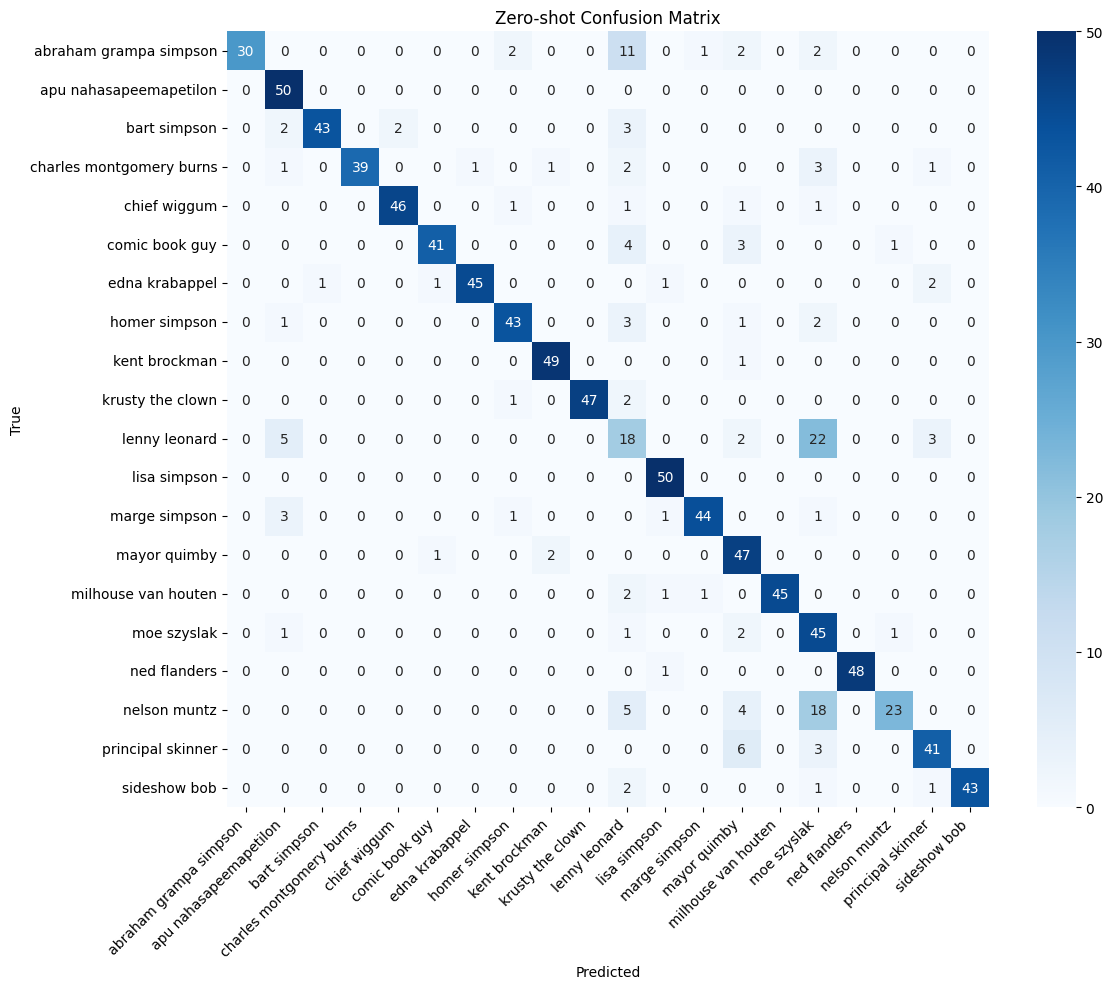

In [ ]:
test_accuracy_openai, text_predictions_openai, text_true = evaluate_zero_shot(model_openai, processor_openai, test_dataset, candidate_labels, class_mapping=None)

Accuracy получилось практически таким же, что в предыдущем пункте у модели microsoft/beit-base-patch16-224. Изначально было около 0.5, но помогло то, что я убрала нижние подчеркивания в названиях классов.

Большинство классов распознаются очень хорошо.
Есть проблемы с некоторыми персонажами (lenny leonard, moe szyslak, nelson muntz)

**SigLIP2**

In [ ]:
from transformers import AutoModelForZeroShotImageClassification, AutoProcessor

processor_siglip = AutoProcessor.from_pretrained("google/siglip2-base-patch16-224")
model_siglip = AutoModelForZeroShotImageClassification.from_pretrained("google/siglip2-base-patch16-224")
model_siglip.to(device)


preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/34.4M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

SiglipModel(
  (text_model): SiglipTextTransformer(
    (embeddings): SiglipTextEmbeddings(
      (token_embedding): Embedding(256000, 768)
      (position_embedding): Embedding(64, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (self_attn): SiglipAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): SiglipMLP(
            (activation_fn): PytorchGELUTanh()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_

Zero-shot accuracy on test samples: 0.0566
Classification Report:
                          precision    recall  f1-score   support

  abraham grampa simpson     0.0000    0.0000    0.0000        48
  apu nahasapeemapetilon     0.0000    0.0000    0.0000        50
            bart simpson     0.1216    0.1800    0.1452        50
charles montgomery burns     0.0000    0.0000    0.0000        48
            chief wiggum     0.0000    0.0000    0.0000        50
          comic book guy     0.0000    0.0000    0.0000        49
          edna krabappel     0.0000    0.0000    0.0000        50
           homer simpson     0.0925    0.3200    0.1435        50
           kent brockman     0.0000    0.0000    0.0000        50
        krusty the clown     1.0000    0.0200    0.0392        50
           lenny leonard     0.0000    0.0000    0.0000        50
            lisa simpson     0.2381    0.1000    0.1408        50
           marge simpson     0.0347    0.5000    0.0649        50
         

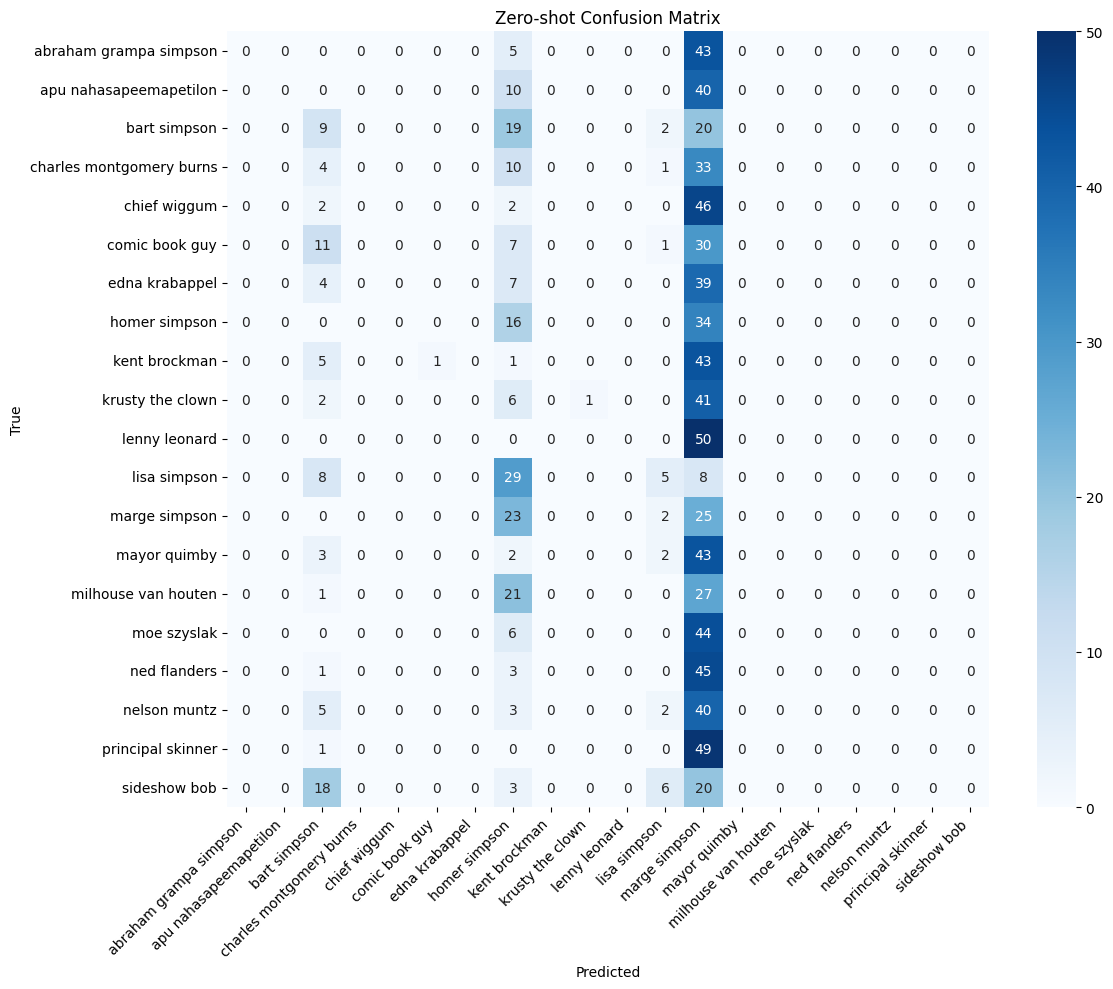

In [ ]:
test_accuracy_siglip, text_predictions_siglip, text_true = evaluate_zero_shot(model_siglip, processor_siglip, test_dataset, candidate_labels, class_mapping=None)

Модель работает очень плохо, не поняла, в чем проблема. Пробовала разными способами, лучше не становится почему-то.

facebook/metaclip-2-worldwide-s16

In [ ]:
from transformers import AutoModel, AutoProcessor

model_meta = AutoModel.from_pretrained("facebook/metaclip-2-worldwide-s16")
processor_meta = AutoProcessor.from_pretrained("facebook/metaclip-2-worldwide-s16")
model_meta.to(device)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.56G [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/515 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/18.2M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/61.3M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

MetaClip2Model(
  (text_model): MetaClip2TextTransformer(
    (embeddings): MetaClip2TextEmbeddings(
      (token_embedding): Embedding(901629, 384)
      (position_embedding): Embedding(77, 384)
    )
    (encoder): MetaClip2Encoder(
      (layers): ModuleList(
        (0-11): 12 x MetaClip2EncoderLayer(
          (self_attn): MetaClip2Attention(
            (k_proj): Linear(in_features=384, out_features=384, bias=True)
            (v_proj): Linear(in_features=384, out_features=384, bias=True)
            (q_proj): Linear(in_features=384, out_features=384, bias=True)
            (out_proj): Linear(in_features=384, out_features=384, bias=True)
          )
          (layer_norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
          (mlp): MetaClip2MLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=384, out_features=1536, bias=True)
            (fc2): Linear(in_features=1536, out_features=384, bias=True)
          )
          (layer_norm2

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:2863: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


Zero-shot accuracy on test samples: 0.3242
Classification Report:
                          precision    recall  f1-score   support

  abraham grampa simpson     0.0000    0.0000    0.0000        48
  apu nahasapeemapetilon     0.3379    0.9800    0.5026        50
            bart simpson     0.9756    0.8000    0.8791        50
charles montgomery burns     0.0000    0.0000    0.0000        48
            chief wiggum     0.2222    0.1200    0.1558        50
          comic book guy     0.0000    0.0000    0.0000        49
          edna krabappel     0.5256    0.8200    0.6406        50
           homer simpson     0.5000    0.1600    0.2424        50
           kent brockman     0.7857    0.4400    0.5641        50
        krusty the clown     0.9565    0.8800    0.9167        50
           lenny leonard     1.0000    0.0400    0.0769        50
            lisa simpson     0.4519    0.9400    0.6104        50
           marge simpson     1.0000    0.0400    0.0769        50
         

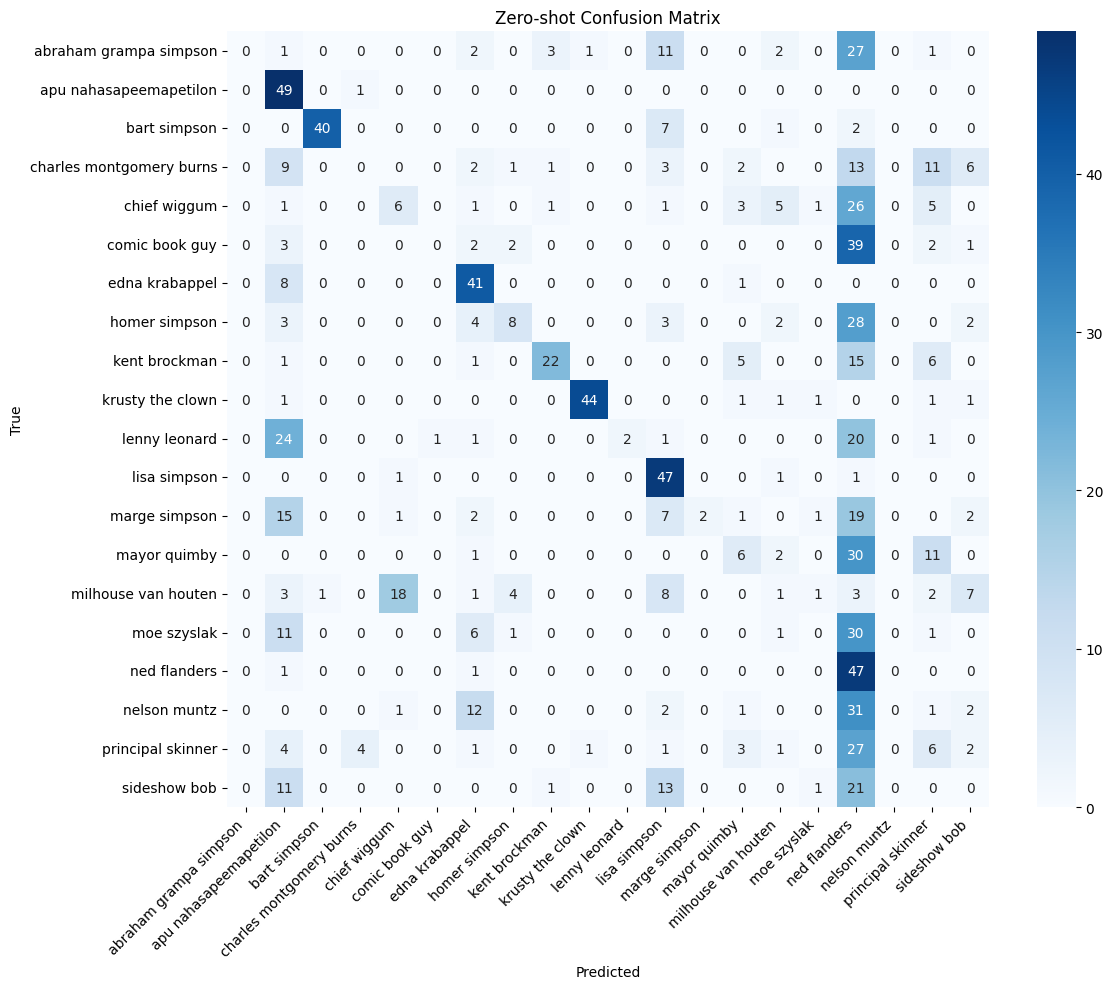

In [ ]:
test_accuracy_meta, text_predictions_meta, text_true = evaluate_zero_shot(model_meta, processor_meta, test_dataset, candidate_labels, class_mapping=None)

У модели очень низкое качество классификации, в разы хуже, чем модель от openai и microsoft/beit-base-patch16-224. Модель имеет слабую обобщающую способность в zero-shot режиме. Некоторые персонажи распознаются хорошо (lenny leonard, marge simpson, krusty the clown), другие совсем не распознаются (abraham grampa simpson, sideshow bob).